# Active learning on the Uncertainty Engine (SDK)

Notebook 03 ran the GP and the acquisition *in this process*. This one builds the same
active-learning loop as **workflows on the remote Uncertainty Engine**, saves them to a
project, and calls them from here by id.

Five workflows — the four exported from the Engine GUI, plus one that saves the
posterior as a reusable dataset:

| Workflow | Nodes | Purpose |
| --- | --- | --- |
| **Train model** | `LoadDataset` → `FilterDataset` ×2 → `ModelConfig` → `TrainModel` → `Save` | Fit a GP to the campaign so far |
| **Active Learning** | `LoadModel` → `Recommend` → `Save` | Choose the next test temperature |
| **Temp to Energy — GP plot** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `UncertaintyPlot` | The model visualisation |
| **Predict slice** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `Save` ×2 | The same posterior, **saved** as project datasets |
| **Validate energy model** | `LoadModel` + `LoadDataset` → `FilterDataset` ×2 → `PredictModel` → `ScoreModel` + `ParityPlot` | Score against held-out data |

### The loop

Each iteration uploads the grown campaign **under the same resource name**, which the
Engine stores as a new *version* of the same resource id. The saved workflows already
point at that id, so they need no edits between iterations — we just call them again.

### Two environments

The engine library and the SDK are both published as `uncertainty-engine` and both
provide a top-level `uncertainty_engine` package — one is in-process modelling, the other
a remote API client. They cannot coexist in one virtualenv.

```bash
uv venv .venv-sdk --python 3.12
uv pip install --python .venv-sdk -e ".[sdk]"
uv pip install --python .venv-sdk pandas numpy pyyaml pydantic matplotlib
```

**Run this notebook on the `.venv-sdk` kernel.** The simulator has no engine-library
dependency, so it runs here too — the whole loop fits on one kernel.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dbtt import backend
from dbtt import sdk_workflows as W
from dbtt.simulator import CharpySimulator, ENERGY_COL, TEMPERATURE_COL

print(backend.describe())

{'backend': 'sdk', 'version': '0.15.0', 'remote_workflows': True}


In [2]:
if not backend.has_sdk():
    raise SystemExit(
        "This notebook needs the SDK environment. Start it on the .venv-sdk kernel — "
        "see the setup block above."
    )

## Credentials and project

`load_credentials()` reads Colab secrets first, then `.env`, and reports only *where*
the credentials came from — never their values. The project must already exist: projects
are created in the Engine GUI, not from the SDK.

In [3]:
source = W.load_credentials("../.env")
print(f"credentials from: {source}")

client, project_id = W.connect()
print(f"project {W.project_name()!r} -> {project_id}")

credentials from: dotenv


project 'Test' -> 6ae27221bac4a9e13468f79d


## The campaign

The simulator stands in for the test house. The initial design is the two limits of the
testable range: they pin the shelves the transition sits between, without which the
curve is unidentifiable.

In [4]:
BOUNDS = (-120.0, 100.0)
SEED_TEMPERATURES = [BOUNDS[0], BOUNDS[1]]
ITERATIONS = 4
ACQUISITION = "qNIPV"

DATASET_NAME = "dbtt_campaign"
MODEL_NAME = "dbtt_gp"
POINTS_NAME = "dbtt_next_point"
MEAN_NAME = "dbtt_gp_mean"
UNCERTAINTY_NAME = "dbtt_gp_sd"

simulator = CharpySimulator()
campaign = simulator.run(SEED_TEMPERATURES, start_index=1)
print(f"true DBTT: {simulator.dbtt} C")
campaign[[TEMPERATURE_COL, ENERGY_COL]]

true DBTT: -40.0 C


,Test temperature (C),Energy absorbed (J)
0,-120.0,6.39
1,100.0,196.94


## Upload, then build and save the four workflows

The dataset has to exist before the graphs can point at it, so it is uploaded first.
`save_workflow` returns an id; after this the workflows are visible in the Engine GUI,
where they can be inspected, re-run and edited.

In [5]:
dataset_id = W.upload_dataset(client, project_id, campaign, DATASET_NAME)
print(f"dataset resource: {dataset_id}")

dataset resource: 6ae273e3bac4a9e13468f79e


In [6]:
training = W.build_training_workflow(client, project_id, dataset_id, MODEL_NAME)
training_id = W.save_workflow(client, project_id, training, "Train model")

# Training has to run once before a model resource exists for the others to load.
W.run_saved(client, project_id, training_id)
model_id = client.resources.get_resource_id_by_name(
    resource_type="model", project_id=project_id, name=MODEL_NAME
)
print(f"model resource: {model_id}")

model resource: 6ae273fdbac4a9e13468f7a3


In [7]:
recommending = W.build_recommendation_workflow(
    client, project_id, model_id, POINTS_NAME, acquisition=ACQUISITION
)
plotting = W.build_gp_plot_workflow(client, project_id, model_id, BOUNDS)
predicting = W.build_prediction_workflow(
    client, project_id, model_id, BOUNDS, MEAN_NAME, UNCERTAINTY_NAME
)
validating = W.build_validation_workflow(client, project_id, model_id, dataset_id)

recommending_id = W.save_workflow(client, project_id, recommending, "Active Learning - Reduce uncertainty")
plotting_id = W.save_workflow(client, project_id, plotting, "Temp to Energy - GP plot")
predicting_id = W.save_workflow(client, project_id, predicting, "Predict slice")
validating_id = W.save_workflow(client, project_id, validating, "Validate energy model")

for name, wid in [
    ("Train model", training_id),
    ("Active Learning - Reduce uncertainty", recommending_id),
    ("Temp to Energy - GP plot", plotting_id),
    ("Predict slice", predicting_id),
    ("Validate energy model", validating_id),
]:
    print(f"{name:40s} {wid}")

Train model                              6ae273e5bac4a9e13468f7a1
Active Learning - Reduce uncertainty     6ae27401bac4a9e13468f7a6
Temp to Energy - GP plot                 6ae27402bac4a9e13468f7a8
Predict slice                            6ae27d4dbac4a9e13468f81b
Validate energy model                    6ae27402bac4a9e13468f7aa


## Reading results back

Only some node outputs come back as *values*. `UncertaintyPlot` returns the whole
posterior inline (`x_vals`, `mean`, `std`), which is why it is what we plot;
`PredictModel`'s own handles, and `Recommend`'s, return S3 references that would each
need a separate download. The recommended points are therefore read from the resource
the `Save` node wrote.

`sdk_workflows` wraps both of those as `uncertainty_curve()` and `recommended_points()`.

## The loop

Train → visualise → recommend → test → append → re-upload. Each iteration re-uploads the
campaign under the same name, so the saved workflows keep working untouched.

In [8]:
history = []

for iteration in range(1, ITERATIONS + 1):
    # 1. Train on everything measured so far.
    W.run_saved(client, project_id, training_id)

    # 2. The model visualisation, for the plot below.
    curve = W.uncertainty_curve(W.run_saved(client, project_id, plotting_id))

    # 3. Ask the acquisition where to test next.
    points = W.recommended_points(
        client, project_id, W.run_saved(client, project_id, recommending_id)
    )
    picked = [float(v) for v in points[TEMPERATURE_COL]]

    history.append({
        "iteration": iteration,
        "n_tests": len(campaign),
        "curve": curve,
        "observed": campaign[[TEMPERATURE_COL, ENERGY_COL]].copy(),
        "picked": picked,
    })
    print(f"iteration {iteration}: {len(campaign)} tests -> next at {picked}")

    # 4. Run those tests on the simulator and grow the campaign.
    new_rows = simulator.run(picked, start_index=len(campaign) + 1)
    campaign = pd.concat([campaign, new_rows], ignore_index=True)

    # 5. Re-upload: a new version of the same resource id.
    W.upload_dataset(client, project_id, campaign, DATASET_NAME)

print(f"\nfinished with {len(campaign)} tests")

iteration 1: 2 tests -> next at [-5.743567103375362]


iteration 2: 3 tests -> next at [-44.95147733017802]


iteration 3: 4 tests -> next at [49.381426923584726]


iteration 4: 5 tests -> next at [-84.31271208450198]



finished with 6 tests


## What the model learned

One panel per iteration: the GP posterior (mean and ±2sd band) against the true
transition curve, the tests done so far, and — the dashed line — where the acquisition
chose to test next. Watch the band collapse around the transition, which is where the
curve is least certain and most informative.

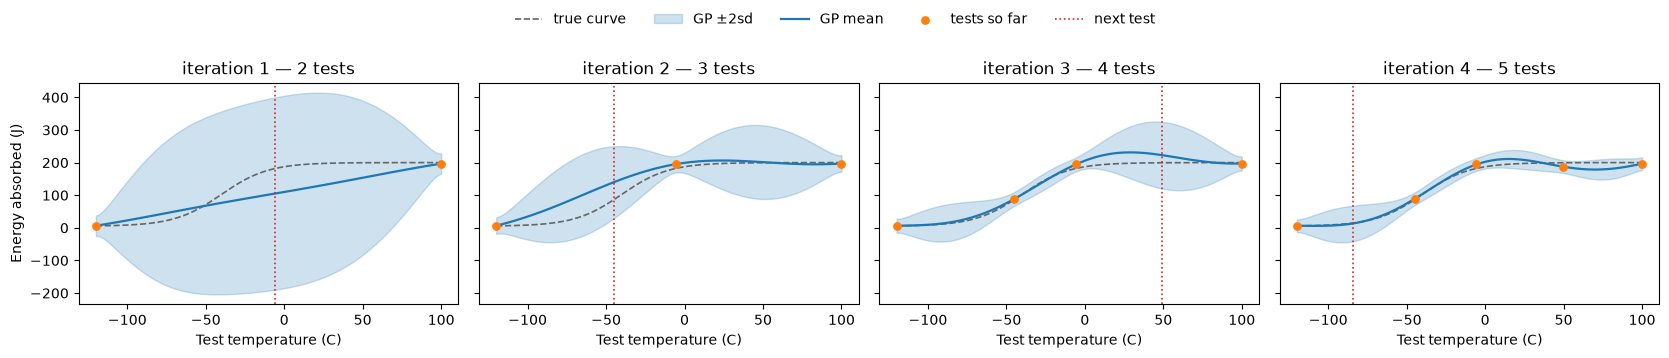

In [9]:
grid = np.linspace(*BOUNDS, 400)
truth = simulator.true_curve(grid)

fig, axes = plt.subplots(
    1, len(history), figsize=(4.2 * len(history), 3.6), sharex=True, sharey=True
)
axes = np.atleast_1d(axes)

for ax, step in zip(axes, history):
    curve = step["curve"]
    t = curve[TEMPERATURE_COL].to_numpy()
    mean, sd = curve["mean"].to_numpy(), curve["sd"].to_numpy()

    ax.plot(grid, truth, color="0.4", lw=1.2, ls="--", label="true curve")
    ax.fill_between(t, mean - 2 * sd, mean + 2 * sd, alpha=0.22, color="C0", label="GP ±2sd")
    ax.plot(t, mean, color="C0", lw=1.6, label="GP mean")
    ax.scatter(
        step["observed"][TEMPERATURE_COL], step["observed"][ENERGY_COL],
        s=28, color="C1", zorder=3, label="tests so far",
    )
    for temperature in step["picked"]:
        ax.axvline(temperature, color="C3", lw=1.2, ls=":", label="next test")

    # The count goes in the title: a shared legend can only carry one label,
    # so putting it there would show every panel the last panel's count.
    ax.set_title(f"iteration {step['iteration']} — {step['n_tests']} tests")
    ax.set_xlabel("Test temperature (C)")

axes[0].set_ylabel("Energy absorbed (J)")
handles, labels = axes[0].get_legend_handles_labels()
seen = dict(zip(labels, handles))
fig.legend(seen.values(), seen.keys(), loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

## Where the acquisition chose to test

Every chosen temperature, in order. An uncertainty-reduction acquisition should cluster
these around the transition rather than spreading them evenly — the shelves are already
pinned by the initial design, so there is nothing left to learn out there.

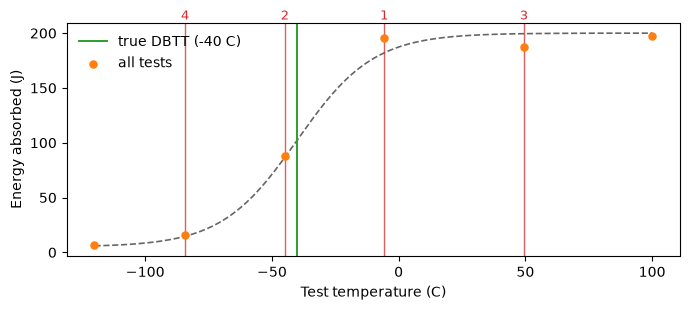

In [10]:
picked = [(step["iteration"], t) for step in history for t in step["picked"]]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(grid, truth, color="0.4", lw=1.2, ls="--")
ax.axvline(simulator.dbtt, color="C2", lw=1.4, label=f"true DBTT ({simulator.dbtt:g} C)")
for iteration, temperature in picked:
    ax.axvline(temperature, color="C3", lw=1.0, alpha=0.75)
    ax.annotate(
        str(iteration), (temperature, ax.get_ylim()[1]),
        ha="center", va="bottom", fontsize=9, color="C3",
    )
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=26, color="C1", zorder=3, label="all tests",
)
ax.set_xlabel("Test temperature (C)")
ax.set_ylabel("Energy absorbed (J)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## The posterior as a saved dataset

`Temp to Energy - GP plot` returns a plot payload that lives only as long as the job.
**Predict slice** runs the same prediction but *saves* the posterior mean and uncertainty
as project datasets, so they persist, can be opened in the GUI, and can be downloaded and
compared later.

Mean and uncertainty are separate resources, because `PredictModel` emits them as separate
handles and there is no node here that joins two datasets. `saved_prediction()` downloads
both and puts them beside the grid, which comes back inline with the job.

In [11]:
saved = W.saved_prediction(
    client, project_id, W.run_saved(client, project_id, predicting_id)
)
print(f"saved as {MEAN_NAME!r} and {UNCERTAINTY_NAME!r} in the project")
saved.head()

saved as 'dbtt_gp_mean' and 'dbtt_gp_sd' in the project


,Test temperature (C),mean,sd
0,-120.0,6.348740,9.859983
1,-117.8,6.278595,10.256775
2,-115.6,6.199006,11.399056
3,-113.4,6.123074,12.997226
4,-111.2,6.064982,14.813295


Being an ordinary frame, it drops straight onto a plot — here the final posterior read
back from the project, against the truth and the campaign that produced it.

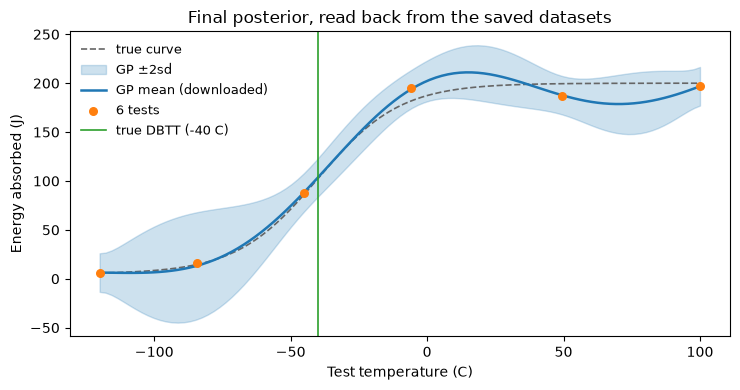

In [12]:
t = saved[TEMPERATURE_COL].to_numpy()
mean, sd = saved["mean"].to_numpy(), saved["sd"].to_numpy()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(grid, truth, color="0.4", lw=1.2, ls="--", label="true curve")
ax.fill_between(t, mean - 2 * sd, mean + 2 * sd, alpha=0.22, color="C0", label="GP ±2sd")
ax.plot(t, mean, color="C0", lw=1.8, label="GP mean (downloaded)")
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=30, color="C1", zorder=3, label=f"{len(campaign)} tests",
)
ax.axvline(simulator.dbtt, color="C2", lw=1.2, label=f"true DBTT ({simulator.dbtt:g} C)")
ax.set_xlabel("Test temperature (C)")
ax.set_ylabel("Energy absorbed (J)")
ax.set_title("Final posterior, read back from the saved datasets")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Validation

The validation workflow scores the final model and returns a parity plot. Here it is run
against the campaign itself, so these are *training* scores — swap `dataset_id` for a
held-out resource to get an honest generalisation estimate.

In [13]:
results = W.outputs(W.run_saved(client, project_id, validating_id))
W.as_frame(results["Score_scores"])

,metric_name,score
0,MSE,2.074846
1,RMSE,1.440432
2,R2,0.999694


## Notes

- **Resource versioning is what makes the loop cheap.** Re-uploading under the same name
  creates a new version of the same resource id, so the saved workflows never need
  editing. `run_saved(..., overrides={("Active Learning", "acquisition_function"): ...})`
  is there for the cases where you *do* want to vary something.
- **The band is the predictive standard deviation**, so it plateaus at the material's
  test-to-test scatter rather than shrinking to zero.
- **A plot payload is not a dataset.** `UncertaintyPlot` packages the posterior for the
  GUI and it vanishes with the job; **Predict slice** saves it as project resources that
  outlive the run. Use the first to watch the loop, the second to keep the result.
- **Node versions are resolved from the Node Registry at run time.** The builders do not
  pin versions when a client is present, so they follow whatever the Engine serves.